# Session 3: Simple GNN for Network Optimisation

This notebook uses the LSTM predictions from Session 2 and trains a real Graph Convolutional Network (GCN).

**GNN representation**
- Node: one geographic area
- Edge: connection to a nearby area
- Node features: predicted RSRP, observation count and coordinates
- Target: low, medium or high network optimisation priority

**Required file:** `lstm_rsrp_predictions.csv`

## 1. Install libraries

In [50]:
%pip install -q pandas numpy matplotlib folium networkx scikit-learn tensorflow

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [52]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
import networkx as nx

from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, Dropout

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 3. Load LSTM predictions from Session 2

In [54]:
PATH = Path("lstm_rsrp_predictions.csv")

if not PATH.exists():
    raise FileNotFoundError(
        "Run Session 2 first to create lstm_rsrp_predictions.csv"
    )

data = pd.read_csv(PATH)

required = ["Latitude", "Longitude", "Predicted_RSRP"]
missing = [column for column in required if column not in data.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

data = data.dropna(subset=required).copy()

print("Prediction rows:", len(data))
display(data.head())

Prediction rows: 3460


,SessionID,Timestamp,Latitude,Longitude,Actual_RSRP,Predicted_RSRP,Absolute_Error_dB
0,20,2025-03-06 11:48:23,3.056521,101.594241,-1.189042,-81.632740,80.443694
1,20,2025-03-06 11:48:24,3.056521,101.594290,-1.365073,-98.002380,96.637307
2,20,2025-03-06 11:48:26,3.056598,101.594292,-1.101026,-102.072690,100.971667
3,20,2025-03-06 11:48:28,3.056598,101.594292,-0.660947,-100.370544,99.709597
4,20,2025-03-06 11:48:28,3.056751,101.594290,-0.660947,-97.309240,96.648295


## 4. Group nearby measurements into graph nodes

Coordinates rounded to three decimal places are treated as one geographic area.

In [56]:
data["Lat_Grid"] = data["Latitude"].round(3)
data["Lon_Grid"] = data["Longitude"].round(3)

areas = (
    data.groupby(["Lat_Grid", "Lon_Grid"], as_index=False)
    .agg(
        Latitude=("Latitude", "mean"),
        Longitude=("Longitude", "mean"),
        Predicted_RSRP=("Predicted_RSRP", "mean"),
        Observation_Count=("Predicted_RSRP", "size")
    )
)

if len(areas) < 4:
    raise ValueError("At least four geographic areas are required.")

print("Graph nodes:", len(areas))
display(areas.head())

Graph nodes: 92


,Lat_Grid,Lon_Grid,Latitude,Longitude,Predicted_RSRP,Observation_Count
0,3.057,101.594,3.056923,101.594252,-97.844849,12
1,3.058,101.594,3.057993,101.594144,-97.629368,11
2,3.059,101.594,3.059108,101.594099,-91.241161,13
3,3.060,101.594,3.059993,101.594103,-97.011718,9
4,3.060,101.603,3.060489,101.603434,-107.439924,3


## 5. Create the optimisation-priority labels

- Low priority: RSRP ≥ −90 dBm
- Medium priority: −105 dBm ≤ RSRP < −90 dBm
- High priority: RSRP < −105 dBm

These are teaching labels created from the predicted RSRP.

In [58]:
def create_label(rsrp):
    if rsrp >= -90:
        return 0       # Low priority
    elif rsrp >= -105:
        return 1       # Medium priority
    else:
        return 2       # High priority

label_names = np.array(["Low", "Medium", "High"])

areas["Label"] = areas["Predicted_RSRP"].apply(create_label)
areas["Actual_Priority"] = label_names[areas["Label"]]

print(areas["Actual_Priority"].value_counts())

Actual_Priority
Low       46
Medium    44
High       2
Name: count, dtype: int64


## 6. Create node features

Every graph node receives four features. Scaling makes their numerical ranges comparable.

In [60]:
feature_names = [
    "Predicted_RSRP",
    "Observation_Count",
    "Latitude",
    "Longitude"
]

X = areas[feature_names].to_numpy(np.float32)
X = StandardScaler().fit_transform(X).astype(np.float32)

y = areas["Label"].to_numpy(np.int32)

print("Node feature matrix:", X.shape)
print("Labels:", y.shape)

Node feature matrix: (92, 4)
Labels: (92,)


## 7. Connect every node to its three nearest geographic neighbours

The adjacency matrix records the edges used by the GNN.

In [62]:
coordinates = areas[["Latitude", "Longitude"]].to_numpy()

number_of_neighbours = min(3, len(areas) - 1)

A = kneighbors_graph(
    coordinates,
    n_neighbors=number_of_neighbours,
    mode="connectivity",
    include_self=False
).toarray().astype(np.float32)

# Make every connection bidirectional.
A = np.maximum(A, A.T)

# Add self-connections.
A = A + np.eye(len(areas), dtype=np.float32)

# Normalise the adjacency matrix: D^(-1/2) A D^(-1/2)
degree = A.sum(axis=1)
D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degree, 1e-8)))
A_normalised = (D_inv_sqrt @ A @ D_inv_sqrt).astype(np.float32)

graph = nx.from_numpy_array(A - np.eye(len(areas)))

print("Nodes:", graph.number_of_nodes())
print("Edges:", graph.number_of_edges())

Nodes: 92
Edges: 163


## 8. Display the graph

Students can now see the nodes and geographic connections used by the GNN.

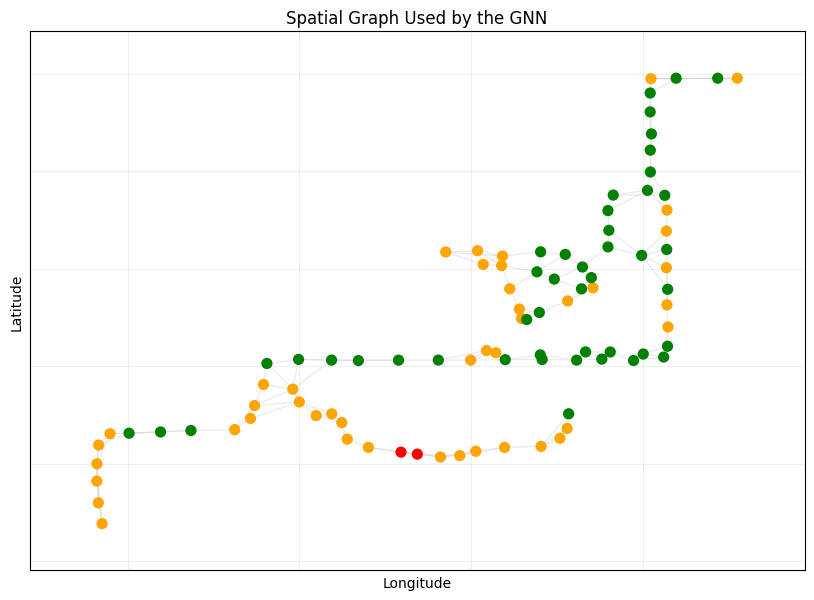

In [64]:
positions = {
    i: (areas.loc[i, "Longitude"], areas.loc[i, "Latitude"])
    for i in range(len(areas))
}

colours = areas["Actual_Priority"].map({
    "High": "red",
    "Medium": "orange",
    "Low": "green"
}).tolist()

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(
    graph, positions,
    edge_color="lightgray",
    alpha=0.5,
    width=0.8
)
nx.draw_networkx_nodes(
    graph, positions,
    node_color=colours,
    node_size=50
)
plt.title("Spatial Graph Used by the GNN")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)
plt.show()

## 9. Split nodes into training, validation and test groups

In [66]:
indices = np.arange(len(areas))
np.random.shuffle(indices)

n_train = max(1, int(0.70 * len(indices)))
n_validation = max(1, int(0.15 * len(indices)))

train_indices = indices[:n_train]
validation_indices = indices[n_train:n_train + n_validation]
test_indices = indices[n_train + n_validation:]

if len(test_indices) == 0:
    test_indices = validation_indices

train_mask = np.zeros(len(areas), dtype=np.float32)
validation_mask = np.zeros(len(areas), dtype=np.float32)

train_mask[train_indices] = 1.0
validation_mask[validation_indices] = 1.0

print("Training nodes:", len(train_indices))
print("Validation nodes:", len(validation_indices))
print("Test nodes:", len(test_indices))

Training nodes: 64
Validation nodes: 13
Test nodes: 15


## 10. Build a simple two-layer GNN

The key GNN operation is `A @ X`. It combines each node's information with information from nearby nodes.

In [68]:
class SimpleGCN(Model):
    def __init__(self, adjacency_matrix):
        super().__init__()
        self.A = tf.constant(adjacency_matrix, dtype=tf.float32)
        self.gcn_layer_1 = Dense(16, activation="relu")
        self.dropout = Dropout(0.20)
        self.gcn_layer_2 = Dense(8, activation="relu")
        self.classifier = Dense(3, activation="softmax")

    def call(self, node_features, training=False):
        # First message-passing operation
        neighbour_features = tf.matmul(self.A, node_features)
        hidden = self.gcn_layer_1(neighbour_features)
        hidden = self.dropout(hidden, training=training)

        # Second message-passing operation
        neighbour_hidden = tf.matmul(self.A, hidden)
        hidden = self.gcn_layer_2(neighbour_hidden)

        return self.classifier(hidden)

model = SimpleGCN(A_normalised)

# Run once to build the layers.
_ = model(tf.constant(X))
model.summary()

Model: "simple_gcn_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (92, 16)               │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (92, 8)                │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (92, 3)                │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## 11. Train the GNN

The model learns to classify every node as low, medium or high optimisation priority.

In [70]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

X_tensor = tf.constant(X, dtype=tf.float32)
y_tensor = tf.constant(y, dtype=tf.int32)
train_mask_tensor = tf.constant(train_mask, dtype=tf.float32)
validation_mask_tensor = tf.constant(validation_mask, dtype=tf.float32)

training_losses = []
validation_losses = []

best_validation_loss = np.inf
best_weights = None
wait = 0
patience = 15

for epoch in range(150):
    with tf.GradientTape() as tape:
        probabilities = model(X_tensor, training=True)
        node_losses = tf.keras.losses.sparse_categorical_crossentropy(
            y_tensor, probabilities
        )
        training_loss = tf.reduce_sum(
            node_losses * train_mask_tensor
        ) / tf.maximum(tf.reduce_sum(train_mask_tensor), 1.0)

    gradients = tape.gradient(training_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    validation_probabilities = model(X_tensor, training=False)
    validation_node_losses = tf.keras.losses.sparse_categorical_crossentropy(
        y_tensor, validation_probabilities
    )
    validation_loss = tf.reduce_sum(
        validation_node_losses * validation_mask_tensor
    ) / tf.maximum(tf.reduce_sum(validation_mask_tensor), 1.0)

    training_losses.append(float(training_loss.numpy()))
    validation_losses.append(float(validation_loss.numpy()))

    if validation_loss.numpy() < best_validation_loss:
        best_validation_loss = float(validation_loss.numpy())
        best_weights = model.get_weights()
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping at epoch", epoch + 1)
        break

if best_weights is not None:
    model.set_weights(best_weights)

print("Best validation loss:", round(best_validation_loss, 4))

Early stopping at epoch 53
Best validation loss: 0.43


## 12. Plot the training history

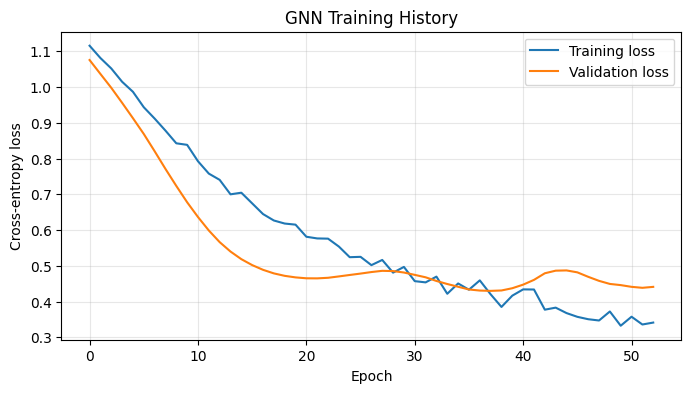

In [72]:
plt.figure(figsize=(8, 4))
plt.plot(training_losses, label="Training loss")
plt.plot(validation_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("GNN Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Evaluate the trained GNN

In [74]:
probabilities = model(X_tensor, training=False).numpy()
predicted_labels = probabilities.argmax(axis=1)

test_accuracy = accuracy_score(
    y[test_indices],
    predicted_labels[test_indices]
)

print(f"Test accuracy: {test_accuracy:.3f}")
print("Confusion matrix:")
print(confusion_matrix(y[test_indices], predicted_labels[test_indices]))

areas["GNN_Label"] = predicted_labels
areas["GNN_Priority"] = label_names[predicted_labels]
areas["GNN_Confidence"] = probabilities.max(axis=1)

display(areas[[
    "Latitude", "Longitude", "Predicted_RSRP",
    "Actual_Priority", "GNN_Priority", "GNN_Confidence"
]].head(15))

Test accuracy: 0.867
Confusion matrix:
[[5 1]
 [1 8]]


,Latitude,Longitude,Predicted_RSRP,Actual_Priority,GNN_Priority,GNN_Confidence
0,3.056923,101.594252,-97.844849,Medium,Medium,0.855863
1,3.057993,101.594144,-97.629368,Medium,Medium,0.855863
2,3.059108,101.594099,-91.241161,Medium,Medium,0.864722
3,3.059993,101.594103,-97.011718,Medium,Medium,0.858026
4,3.060489,101.603434,-107.439924,High,Medium,0.874919
5,3.060345,101.604109,-104.897137,Medium,Medium,0.867346
6,3.060416,101.604670,-102.000280,Medium,Medium,0.855876
7,3.060955,101.594152,-97.140418,Medium,Medium,0.737888
8,3.061257,101.601393,-100.267700,Medium,Medium,0.878659
9,3.060835,101.602008,-104.446549,Medium,Medium,0.868156


## 14. Create the GNN GeoAI optimisation map

In [76]:
def marker_colour(priority):
    return {
        "High": "red",
        "Medium": "orange",
        "Low": "green"
    }[priority]

def action(priority):
    if priority == "High":
        return "Review coverage or add capacity"
    elif priority == "Medium":
        return "Monitor and adjust network parameters"
    return "No immediate action"

map_center = [areas["Latitude"].mean(), areas["Longitude"].mean()]

gnn_map = folium.Map(
    location=map_center,
    zoom_start=14,
    tiles="OpenStreetMap"
)

for _, row in areas.iterrows():
    popup = (
        f"Predicted RSRP: {row['Predicted_RSRP']:.2f} dBm<br>"
        f"GNN priority: {row['GNN_Priority']}<br>"
        f"Confidence: {row['GNN_Confidence']:.2f}<br>"
        f"Action: {action(row['GNN_Priority'])}"
    )

    folium.CircleMarker(
        [row["Latitude"], row["Longitude"]],
        radius=5,
        color=marker_colour(row["GNN_Priority"]),
        fill=True,
        fill_opacity=0.8,
        popup=popup
    ).add_to(gnn_map)

gnn_map.save("session3_simple_gnn_map.html")
gnn_map

## 15. Save the GNN results

In [78]:
areas.to_csv("session3_simple_gnn_results.csv", index=False)

print("Saved:")
print("- session3_simple_gnn_results.csv")
print("- session3_simple_gnn_map.html")

Saved:
- session3_simple_gnn_results.csv
- session3_simple_gnn_map.html


## Teaching summary

1. LSTM predictions are grouped into geographic areas.
2. Every area becomes a graph node.
3. Nearby areas are connected by graph edges.
4. `A @ X` performs GNN message passing.
5. The GNN is trained to predict low, medium or high optimisation priority.
6. The predictions are displayed on a GeoAI map.

### Important limitation

The priority labels are created from predicted RSRP thresholds for teaching. They are not real optimisation labels supplied by a telecommunications operator.